<a href="https://colab.research.google.com/github/sim07hamdani/FDM5-3P-Travaux/blob/main/notebooks/05_scipy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aelkharrim/FDM5-3P/blob/main/notebooks/05_scipy.ipynb)

# Python pour la physique — 5. SciPy : le calcul scientifique de haut niveau

> 💡 **Astuce**
>
> **Rappel** : exécutez les cellules dans l'ordre avec **Maj + Entrée**. Les solutions des exercices sont masquées dans des cellules « Solution » : essayez d'abord par vous-même !

In [1]:
# Cellule de préparation (facultative) : exécutez-la une fois au début.
# Sur Google Colab, NumPy, SciPy, Matplotlib et SymPy sont déjà installés.
import sys
EN_COLAB = 'google.colab' in sys.modules
print('Exécution dans Google Colab' if EN_COLAB else 'Exécution en local')

Exécution dans Google Colab


# Introduction


> 📝 **Note**
>
> Le module `scipy` regroupe des algorithmes de calcul scientifique **de haut niveau**. Il est construit au-dessus de NumPy. Ses principaux sous-modules sont :
>
> | Sous-module          | Contenu                                           |
> | -------------------- | ------------------------------------------------- |
> | `scipy.io`           | entrées/sorties de fichiers                       |
> | `scipy.special`      | fonctions spéciales (Bessel, gamma, erreur…)      |
> | `scipy.linalg`       | algèbre linéaire                                  |
> | `scipy.interpolate`  | interpolation                                     |
> | `scipy.optimize`     | optimisation, recherche de racines, ajustement    |
> | `scipy.stats`        | statistiques et nombres aléatoires                |
> | `scipy.integrate`    | intégration numérique et équations différentielles |
> | `scipy.fft`          | transformées de Fourier rapides                   |
> | `scipy.signal`       | traitement du signal                              |
> | `scipy.ndimage`      | traitement d'images n-dimensionnelles             |


Les sous-modules doivent être importés explicitement, par exemple :

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
import scipy.optimize
import scipy.integrate
import scipy.interpolate
import scipy.linalg
import scipy.special
import scipy.stats
import scipy.fft
import scipy.signal

> 💡 **Astuce**
>
> Avant de programmer un algorithme soi-même, **cherchez toujours s'il existe déjà dans SciPy** : il sera presque toujours plus rapide, plus fiable et mieux testé que votre version.

# Entrées/sorties : `scipy.io`

Charger et enregistrer des fichiers MATLAB™ :

In [3]:
a = np.ones((3, 3))
sp.io.savemat('fichier.mat', {'a': a})  # enregistre un dictionnaire de tableaux
donnees = sp.io.loadmat('fichier.mat')
donnees['a']

array([[1., 1., 1.],
       [1., 1., 1.],
       [1., 1., 1.]])

Charger des images :

```python
import imageio.v3 as iio
img = iio.imread('fichier.png')   # tableau NumPy
```

Pour les fichiers texte de mesures, `np.loadtxt` (carnet 3) suffit le plus souvent. Pour les tableaux de données mélangeant texte et nombres (CSV, Excel), on utilise la bibliothèque **pandas**.

# Fonctions spéciales : `scipy.special`

Les fonctions spéciales sont des fonctions transcendantes que l'on rencontre souvent en physique : Bessel, gamma, fonction d'erreur, polynômes orthogonaux, intégrales elliptiques, etc.

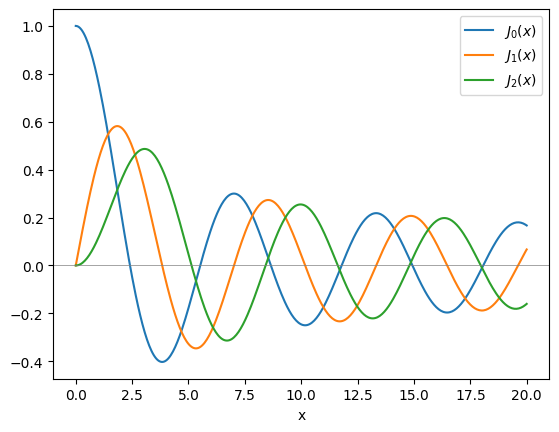

In [4]:
import scipy.special as special

# Fonction de Bessel de première espèce, ordre 0 : modes d'une membrane circulaire
x = np.linspace(0, 20, 400)
for n in range(3):
    plt.plot(x, special.jv(n, x), label=f"$J_{n}(x)$")
plt.axhline(0, color='gray', lw=0.5)
plt.legend()
plt.xlabel("x")
plt.show()

La fonction gamma généralise la factorielle ; la fonction d'erreur apparaît dans la loi normale :

In [5]:
special.gamma(5), special.erf(1.0)

(np.float64(24.0), np.float64(0.8427007929497148))

> **Exemple physique : diffraction par une ouverture circulaire**
>
> L'intensité de la figure de diffraction d'une ouverture circulaire (tache d'Airy) est :
>
> $$I(\theta) = I_0 \left[\frac{2 J_1(x)}{x}\right]^2, \qquad x = \frac{\pi D}{\lambda}\sin\theta$$

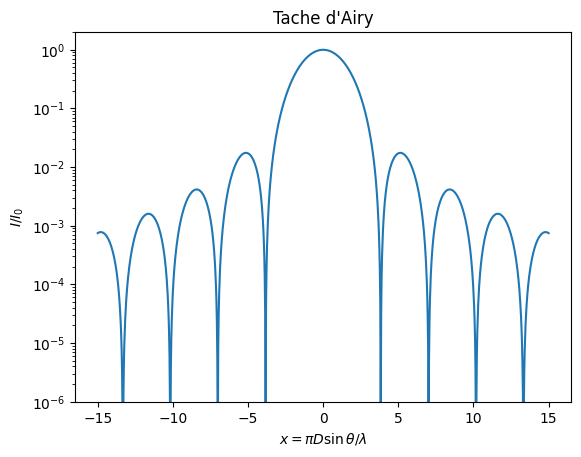

In [6]:
x = np.linspace(-15, 15, 1000)
x[x == 0] = 1e-12
I = (2 * special.jv(1, x) / x)**2

plt.semilogy(x, I)
plt.xlabel(r"$x = \pi D \sin\theta / \lambda$")
plt.ylabel(r"$I / I_0$")
plt.title("Tache d'Airy")
plt.ylim(1e-6, 2)
plt.show()

> **À vous de jouer**
>
> Tracez les polynômes de Legendre $P_0, \dots, P_4$ sur $[-1, 1]$ avec `special.eval_legendre(n, x)`. Ils interviennent dans le développement multipolaire du potentiel.

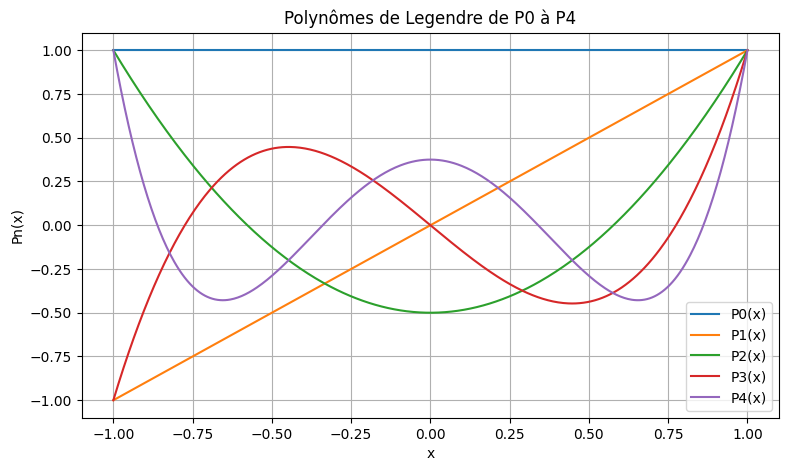

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import special

# Valeurs de x entre -1 et 1
x = np.linspace(-1, 1, 500)

# Tracer les polynômes de Legendre P0 à P4
plt.figure(figsize=(9, 5))

for n in range(5):
    y = special.eval_legendre(n, x)
    plt.plot(x, y, label=f"P{n}(x)")

# Mise en forme du graphique
plt.title("Polynômes de Legendre de P0 à P4")
plt.xlabel("x")
plt.ylabel("Pn(x)")
plt.grid(True)
plt.legend()
plt.show()

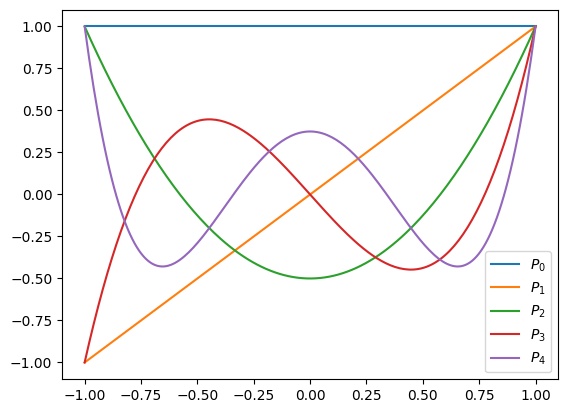

In [8]:
#@title Solution { display-mode: "form" }
x = np.linspace(-1, 1, 200)
for n in range(5):
    plt.plot(x, special.eval_legendre(n, x), label=f"$P_{n}$")
plt.legend()
plt.show()

# Algèbre linéaire : `scipy.linalg`

Le module `scipy.linalg` fournit des fonctionnalités d'algèbre linéaire standard, basées sur les bibliothèques optimisées LAPACK et BLAS (plus complet et plus rapide que `numpy.linalg`).

Le **déterminant** d'une matrice carrée :

In [9]:
A = np.array([[1, 2],
              [3, 4]])
sp.linalg.det(A)

np.float64(-2.0)

L'**inverse** :

In [10]:
iA = sp.linalg.inv(A)
iA

array([[-2. ,  1. ],
       [ 1.5, -0.5]])

In [11]:
A @ iA

array([[1.0000000e+00, 0.0000000e+00],
       [8.8817842e-16, 1.0000000e+00]])

Pour **résoudre un système linéaire** $A\,\mathbf{x} = \mathbf{b}$, utilisez `solve` (plus précis et plus rapide que de calculer l'inverse) :

In [12]:
A = np.array([[2., 1.], [1., 3.]])
b = np.array([1., 2.])
x = sp.linalg.solve(A, b)
x, A @ x - b

(array([0.2, 0.6]), array([ 0.00000000e+00, -2.22044605e-16]))

**Valeurs propres et vecteurs propres** :

In [13]:
A = np.array([[1, 2],
              [3, 4]])
valeurs, vecteurs = sp.linalg.eig(A)
valeurs

array([-0.37228132+0.j,  5.37228132+0.j])

**Décomposition en valeurs singulières (SVD)** :

In [14]:
U, s, Vh = sp.linalg.svd(A)
s

array([5.4649857 , 0.36596619])

> **Exemple physique : modes propres de deux oscillateurs couplés**
>
> Deux masses $m$ reliées à deux murs par des ressorts de raideur $k$, et entre elles par un ressort de raideur $k_c$. Les équations du mouvement s'écrivent $m\ddot{\mathbf{x}} = -K\mathbf{x}$, avec
>
> $$K = \begin{pmatrix} k + k_c & -k_c \\ -k_c & k + k_c \end{pmatrix}$$
>
> Les pulsations propres sont $\omega = \sqrt{\lambda/m}$, où $\lambda$ sont les valeurs propres de $K$.

In [15]:
m, k, kc = 0.5, 20.0, 5.0     # kg, N/m, N/m
K = np.array([[k + kc, -kc],
              [-kc, k + kc]])

lam, modes = sp.linalg.eigh(K)     # eigh : pour les matrices symétriques
omega = np.sqrt(lam / m)
print("Pulsations propres (rad/s) :", omega)
print("Fréquences (Hz)            :", omega / (2 * np.pi))
print("Modes propres (en colonnes) :\n", modes)

Pulsations propres (rad/s) : [6.32455532 7.74596669]
Fréquences (Hz)            : [1.00658424 1.23280889]
Modes propres (en colonnes) :
 [[-0.70710678 -0.70710678]
 [-0.70710678  0.70710678]]


Le premier mode `(1, 1)/√2` correspond aux deux masses qui oscillent **en phase** ; le second `(1, -1)/√2` à l'oscillation **en opposition de phase**.

# Interpolation : `scipy.interpolate`

On dispose de mesures en quelques points et on veut estimer la grandeur entre ces points. Créons des données bruitées :

In [16]:
rng = np.random.default_rng(0)
mesure_t = np.linspace(0, 1, 10)
bruit = (rng.random(10) - 0.5) * 1e-1
mesure_x = np.sin(2 * np.pi * mesure_t) + bruit

`interp1d` construit une fonction d'interpolation :

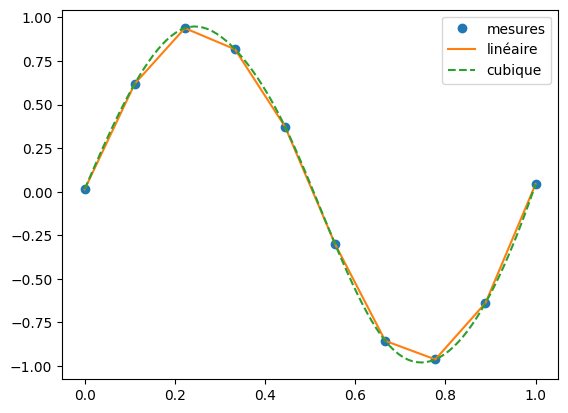

In [17]:
from scipy.interpolate import interp1d

lineaire = interp1d(mesure_t, mesure_x)
cubique = interp1d(mesure_t, mesure_x, kind='cubic')

t_fin = np.linspace(0, 1, 100)
plt.plot(mesure_t, mesure_x, 'o', label='mesures')
plt.plot(t_fin, lineaire(t_fin), '-', label='linéaire')
plt.plot(t_fin, cubique(t_fin), '--', label='cubique')
plt.legend()
plt.show()

> ⚠️ **Attention**
>
> L'interpolation **passe exactement par les points**, y compris par le bruit. Pour extraire une loi à partir de mesures bruitées, on préfère un **ajustement** (voir plus loin).


Les splines permettent aussi de dériver et d'intégrer :

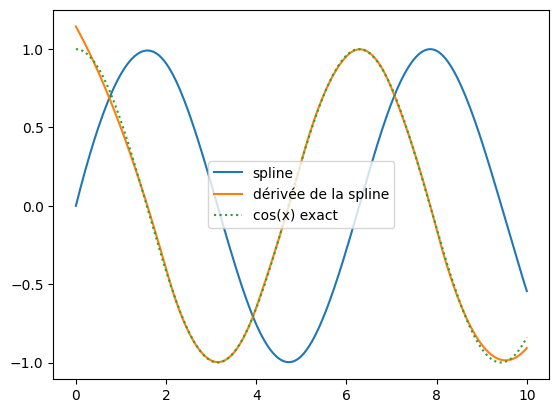

In [18]:
from scipy.interpolate import CubicSpline

x = np.linspace(0, 10, 11)
cs = CubicSpline(x, np.sin(x))
xs = np.linspace(0, 10, 200)

plt.plot(xs, cs(xs), label="spline")
plt.plot(xs, cs(xs, 1), label="dérivée de la spline")
plt.plot(xs, np.cos(xs), ':', label="cos(x) exact")
plt.legend()
plt.show()

# Optimisation et ajustement : `scipy.optimize`

`scipy.optimize` fournit des algorithmes pour la recherche de racines, l'ajustement de courbes et l'optimisation plus générale.

## Recherche de racines

`root_scalar` cherche une racine d'une fonction scalaire (un argument pour lequel la fonction vaut zéro). Comme beaucoup de fonctions de `scipy.optimize`, elle a besoin d'une estimation initiale de la solution, qu'elle affine jusqu'à convergence. Nous fournissons aussi la dérivée pour accélérer la convergence.

In [19]:
def f(x):
    return (x-1)*(x-2)

def df(x):
    return 2*x - 3

x0 = 0  # estimation initiale
res = sp.optimize.root_scalar(f, x0=x0, fprime=df)
res

      converged: True
           flag: converged
 function_calls: 12
     iterations: 6
           root: 1.0
         method: newton

> ⚠️ **Attention**
>
> Aucune des fonctions de `scipy.optimize` qui acceptent une estimation initiale n'est garantie de converger pour toutes les estimations possibles ! (Essayez par exemple `x0=1.5` ci-dessus, où la dérivée est exactement nulle.) Dans ce cas, essayez une autre estimation, changez les options (par exemple en donnant un intervalle `bracket`, voir ci-dessous), ou cherchez si SciPy propose une méthode plus adaptée.


Seule la racine en `1.0` est trouvée. En regardant la fonction, on voit qu'il y a une seconde racine en `2.0`. On peut orienter la recherche vers une racine particulière en changeant l'estimation ou en donnant un intervalle qui ne contient que la racine voulue :

In [20]:
res = sp.optimize.root_scalar(f, bracket=(1.5, 10))
res.root

2.0

Pour les problèmes à plusieurs variables, utilisez `scipy.optimize.root` :

In [21]:
def f(x):
    # intersection du cercle unité et de la droite passant par l'origine
    return [x[0]**2 + x[1]**2 - 1,
            x[1] - x[0]]

res = sp.optimize.root(f, x0=[0, 0])
np.allclose(f(res.x), 0, atol=1e-10)

True

In [22]:
np.allclose(res.x, np.sqrt(2)/2)

True

> **Exemple physique : équation transcendante**
>
> Les niveaux d'énergie d'un puits quantique fini conduisent à des équations comme $\tan(x) = \sqrt{(x_0/x)^2 - 1}$. Un exemple plus simple : à quel instant la position $x(t) = e^{-t}\cos(5t)$ s'annule-t-elle pour la première fois après $t = 0$ ?

In [23]:
x_t = lambda t: np.exp(-t) * np.cos(5 * t)
res = sp.optimize.root_scalar(x_t, bracket=(0, 0.5))
res.root, np.pi / 10   # on attend 5t = π/2, soit t = π/10

(0.3141592653589793, 0.3141592653589793)

## Ajustement de courbes

Supposons que nous ayons des données sinusoïdales mais bruitées :

In [24]:
x_data = np.linspace(-5, 5, num=50)  # 50 valeurs entre -5 et 5
bruit = 0.01 * np.cos(100 * x_data)
a, b = 2.9, 1.5
y_data = a * np.cos(b * x_data) + bruit

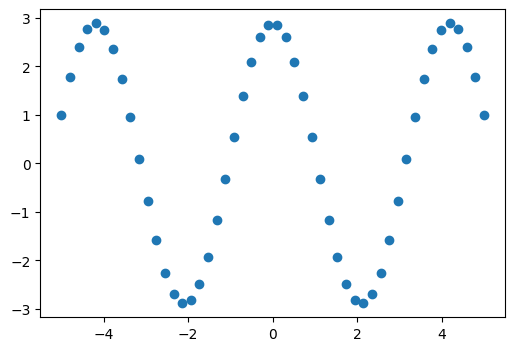

In [25]:
plt.figure(figsize=(6, 4))
plt.scatter(x_data, y_data)
plt.show()

Nous pouvons retrouver l'amplitude, la fréquence et la phase sous-jacentes par un ajustement de courbe aux moindres carrés. Écrivons d'abord une fonction qui prend la variable indépendante en premier argument, et tous les paramètres à ajuster en arguments séparés :

In [26]:
def f(x, a, b, c):
    return a * np.sin(b * x + c)

Nous utilisons ensuite `scipy.optimize.curve_fit` :

In [27]:
params, _ = sp.optimize.curve_fit(f, x_data, y_data, p0=[2, 1, 3])
params

array([2.900026  , 1.50012043, 1.57079633])

In [28]:
ref = [a, b, np.pi/2]  # ce à quoi on s'attend
np.allclose(params, ref, rtol=1e-3)

True

Traçons la courbe ajustée sur les données :

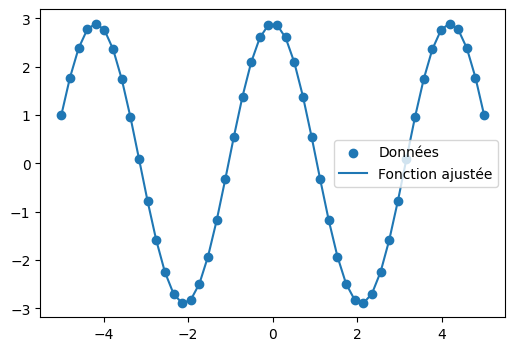

In [29]:
plt.figure(figsize=(6, 4))
plt.scatter(x_data, y_data, label="Données")
plt.plot(x_data, f(x_data, *params), label="Fonction ajustée")
plt.legend(loc="best")
plt.show()

### Incertitudes sur les paramètres

`curve_fit` renvoie aussi la **matrice de covariance** des paramètres, dont la diagonale donne les variances. On peut ainsi donner un résultat sous la forme « valeur ± incertitude ». Prenons un exemple de **décharge d'un condensateur**, $U(t) = U_0 e^{-t/\tau}$, avec des mesures incertaines :

U0  = 5.04 ± 0.11 V
tau = 1.73 ± 0.06 ms


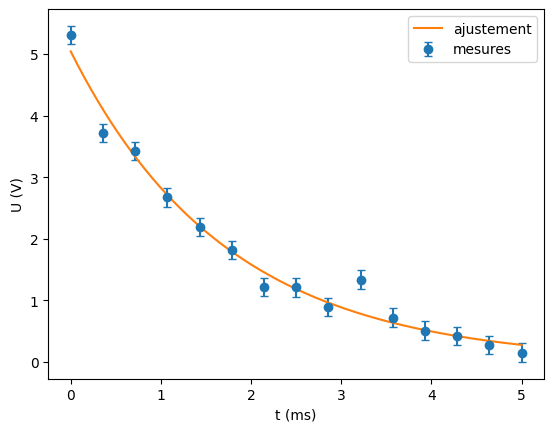

In [30]:
rng = np.random.default_rng(3)
t = np.linspace(0, 5, 15)                          # en ms
U_vrai = lambda t, U0, tau: U0 * np.exp(-t / tau)
sigma = 0.15                                       # incertitude sur U (V)
U = U_vrai(t, 5.0, 1.8) + rng.normal(0, sigma, t.size)

popt, pcov = sp.optimize.curve_fit(U_vrai, t, U, p0=[4, 1],
                                   sigma=sigma * np.ones_like(t), absolute_sigma=True)
incert = np.sqrt(np.diag(pcov))
print(f"U0  = {popt[0]:.2f} ± {incert[0]:.2f} V")
print(f"tau = {popt[1]:.2f} ± {incert[1]:.2f} ms")

tt = np.linspace(0, 5, 200)
plt.errorbar(t, U, yerr=sigma, fmt='o', capsize=3, label="mesures")
plt.plot(tt, U_vrai(tt, *popt), label="ajustement")
plt.xlabel("t (ms)"); plt.ylabel("U (V)"); plt.legend()
plt.show()

> **Exercice : températures en Alaska**
>
>
> Les températures extrêmes en Alaska pour chaque mois, à partir de janvier, sont (en degrés Celsius) :
>
> ```text
> max :  17,  19,  21,  28,  33,  38, 37,  37,  31,  23,  19,  18
> min : -62, -59, -56, -46, -32, -18, -9, -13, -25, -46, -52, -58
> ```
>
> 1. Tracez ces extrema de température.
> 2. Définissez une fonction pouvant décrire les températures min et max. Indice : cette fonction doit avoir une période d'un an, et inclure un décalage temporel.
> 3. Ajustez cette fonction aux données avec `curve_fit`.
> 4. Tracez le résultat. L'ajustement est-il raisonnable ? Sinon, pourquoi ?
> 5. Le décalage temporel est-il le même pour les températures min et max, compte tenu de la précision de l'ajustement ?

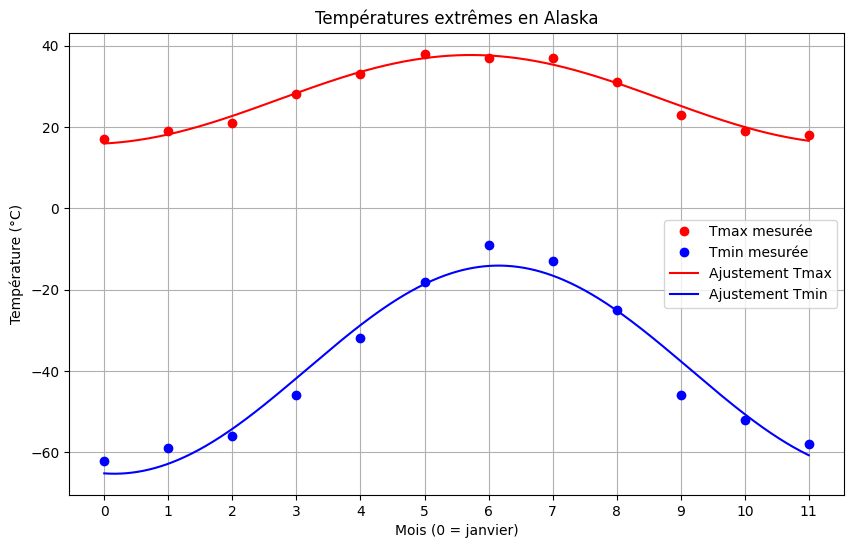

Températures maximales :
T0 = 26.75 °C
Amplitude = 10.93 °C
Décalage = 5.72 mois
Incertitude = 0.1 mois

Températures minimales :
T0 = -39.67 °C
Amplitude = 25.58 °C
Décalage = 6.16 mois
Incertitude = 0.13 mois

Différence des décalages : 0.43 mois
Incertitude sur la différence : 0.17 mois
Décalages non compatibles à environ 2 incertitudes-types.


In [65]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 1. Données : températures mensuelles en Alaska
mois = np.arange(12)

Tmax = np.array([17, 19, 21, 28, 33, 38,
                 37, 37, 31, 23, 19, 18])

Tmin = np.array([-62, -59, -56, -46, -32, -18,
                 -9, -13, -25, -46, -52, -58])

# 2. Fonction sinusoïdale de période 12 mois
def temperature(t, T0, A, decalage):
    return T0 + A * np.cos(2*np.pi*(t-decalage)/12)

# 3. Ajustement avec curve_fit
pmax, covmax = curve_fit(
    temperature, mois, Tmax,
    p0=[np.mean(Tmax), 11, 6]
)

pmin, covmin = curve_fit(
    temperature, mois, Tmin,
    p0=[np.mean(Tmin), 26, 6]
)

# Incertitudes des paramètres
err_max = np.sqrt(np.diag(covmax))
err_min = np.sqrt(np.diag(covmin))

# 4. Tracé des données et ajustements
t = np.linspace(0, 11, 500)

plt.figure(figsize=(10, 6))

plt.plot(mois, Tmax, 'ro', label="Tmax mesurée")
plt.plot(mois, Tmin, 'bo', label="Tmin mesurée")

plt.plot(t, temperature(t, *pmax), 'r-',
         label="Ajustement Tmax")

plt.plot(t, temperature(t, *pmin), 'b-',
         label="Ajustement Tmin")

plt.xlabel("Mois (0 = janvier)")
plt.ylabel("Température (°C)")
plt.title("Températures extrêmes en Alaska")
plt.xticks(mois)
plt.grid(True)
plt.legend()
plt.show()

# 5. Affichage des résultats
print("Températures maximales :")
print("T0 =", round(pmax[0], 2), "°C")
print("Amplitude =", round(pmax[1], 2), "°C")
print("Décalage =", round(pmax[2], 2), "mois")
print("Incertitude =", round(err_max[2], 2), "mois")

print("\nTempératures minimales :")
print("T0 =", round(pmin[0], 2), "°C")
print("Amplitude =", round(pmin[1], 2), "°C")
print("Décalage =", round(pmin[2], 2), "mois")
print("Incertitude =", round(err_min[2], 2), "mois")

# Comparaison des décalages temporels
difference = abs(pmax[2] - pmin[2])
incertitude_diff = np.sqrt(err_max[2]**2 + err_min[2]**2)

print("\nDifférence des décalages :",
      round(difference, 2), "mois")

print("Incertitude sur la différence :",
      round(incertitude_diff, 2), "mois")

if difference <= 2 * incertitude_diff:
    print("Décalages compatibles à environ 2 incertitudes-types.")
else:
    print("Décalages non compatibles à environ 2 incertitudes-types.")

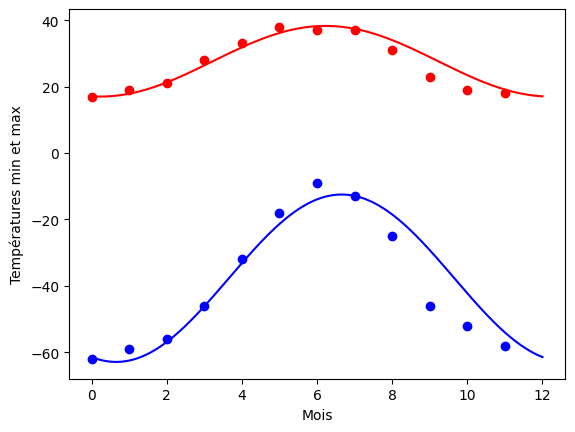

Décalage (max) : -0.22590567614761584 ± 0.0723801316938696
Décalage (min) : -0.6535589138653769 ± 0.09922546316705626


In [32]:
#@title Solution { display-mode: "form" }
temp_max = np.array([17, 19, 21, 28, 33, 38, 37, 37, 31, 23, 19, 18])
temp_min = np.array([-62, -59, -56, -46, -32, -18, -9, -13, -25, -46, -52, -58])

mois = np.arange(12)
plt.plot(mois, temp_max, "ro")
plt.plot(mois, temp_min, "bo")
plt.xlabel("Mois")
plt.ylabel("Températures min et max")

def temperatures_annuelles(temps, moy, ampl, decalage):
    return moy + ampl * np.cos((temps + decalage) * 2 * np.pi / temps.max())

res_max, cov_max = sp.optimize.curve_fit(temperatures_annuelles, mois, temp_max, [20, 10, 0])
res_min, cov_min = sp.optimize.curve_fit(temperatures_annuelles, mois, temp_min, [-40, 20, 0])

jours = np.linspace(0, 12, num=365)
plt.plot(jours, temperatures_annuelles(jours, *res_max), "r-")
plt.plot(jours, temperatures_annuelles(jours, *res_min), "b-")
plt.show()

print("Décalage (max) :", res_max[2], "±", np.sqrt(cov_max[2, 2]))
print("Décalage (min) :", res_min[2], "±", np.sqrt(cov_min[2, 2]))
# Les deux décalages sont compatibles compte tenu des incertitudes :
# le temps de décalage est le même pour les minima et les maxima.

## Optimisation (recherche de minimum)

Considérons la fonction $f(x) = x^4 - 3x^2 + x$. Ses minima ne sont pas évidents à repérer à vue ; traçons-la :

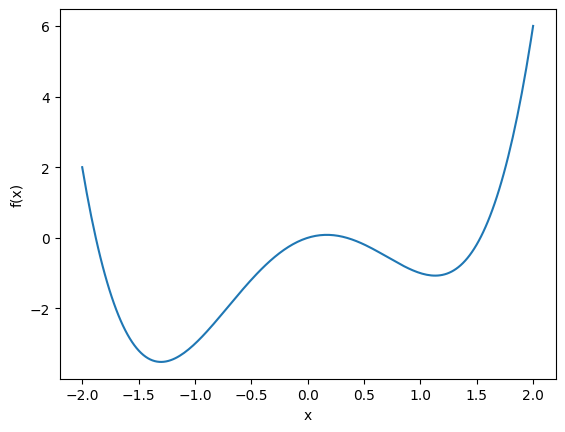

In [33]:
def f(x):
    return x**4 - 3 * x**2 + x

x = np.linspace(-2, 2, 200)
plt.plot(x, f(x))
plt.xlabel("x"); plt.ylabel("f(x)")
plt.show()

`scipy.optimize.minimize` trouve un **minimum local** à partir d'une estimation initiale :

In [34]:
res1 = sp.optimize.minimize(f, x0=-2)
res2 = sp.optimize.minimize(f, x0=2)
print("depuis x0 = -2 :", res1.x, res1.fun)
print("depuis x0 = +2 :", res2.x, res2.fun)

depuis x0 = -2 : [-1.30083949] -3.5139050389347464
depuis x0 = +2 : [1.13090187] -1.0702301817735662


Selon le point de départ, on tombe sur un minimum différent : seul l'un d'eux est le minimum **global**. Pour chercher un minimum global, on peut utiliser par exemple `scipy.optimize.differential_evolution` ou `basinhopping`.


> **Exercice : minimiser une énergie potentielle**
>
> L'énergie d'interaction entre deux atomes est modélisée par le potentiel de Lennard-Jones, $V(r) = 4\varepsilon\left[(\sigma/r)^{12} - (\sigma/r)^6\right]$. Pour $\varepsilon = 1$ et $\sigma = 1$, trouvez numériquement la distance d'équilibre $r_{\min}$ (où $V$ est minimal), et comparez avec la valeur théorique $2^{1/6}\sigma \approx 1{,}122$.

Distance d'équilibre numérique : 1.122462
Distance d'équilibre théorique : 1.122462
Énergie potentielle minimale : -1.0
Erreur absolue : 7.331049256542599e-08


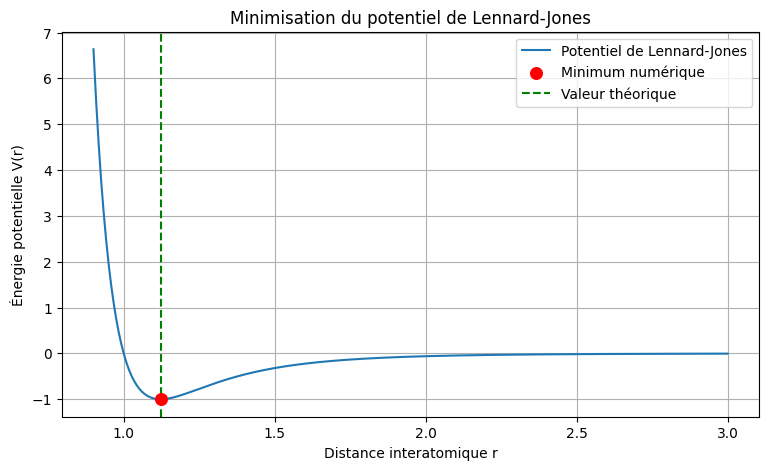

In [69]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

# Données
epsilon = 1
sigma = 1

# Potentiel de Lennard-Jones
def V(r):
    return 4 * epsilon * ((sigma/r)**12 - (sigma/r)**6)

# 1. Minimisation numérique
resultat = minimize_scalar(V, bounds=(0.8, 3), method="bounded")

r_min = resultat.x
V_min = resultat.fun

# 2. Valeur théorique
r_theorique = 2**(1/6) * sigma

# 3. Comparaison
print("Distance d'équilibre numérique :", round(r_min, 6))
print("Distance d'équilibre théorique :", round(r_theorique, 6))
print("Énergie potentielle minimale :", round(V_min, 6))
print("Erreur absolue :", abs(r_min - r_theorique))

# 4. Tracé du potentiel
r = np.linspace(0.9, 3, 500)

plt.figure(figsize=(9, 5))
plt.plot(r, V(r), label="Potentiel de Lennard-Jones")

plt.scatter(r_min, V_min, color="red", s=70,
            label="Minimum numérique", zorder=5)

plt.axvline(r_theorique, color="green",
            linestyle="--", label="Valeur théorique")

plt.xlabel("Distance interatomique r")
plt.ylabel("Énergie potentielle V(r)")
plt.title("Minimisation du potentiel de Lennard-Jones")
plt.grid(True)
plt.legend()
plt.show()

In [68]:
#@title Solution { display-mode: "form" }
def V(r, eps=1.0, sigma=1.0):
    return 4 * eps * ((sigma / r)**12 - (sigma / r)**6)

res = sp.optimize.minimize(lambda r: V(r[0]), x0=[1.5])
print("r_min numérique :", res.x[0])
print("r_min théorique :", 2**(1/6))

r_min numérique : 1.1224620892911676
r_min théorique : 1.122462048309373


# Statistiques et nombres aléatoires : `scipy.stats`

## Distributions statistiques

`scipy.stats` fournit de nombreuses distributions de probabilité. Par exemple, la loi normale :

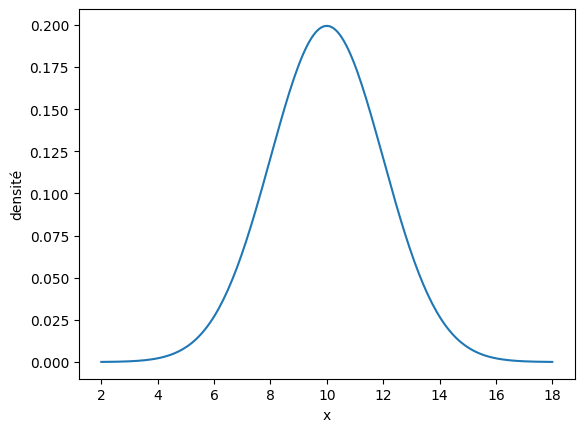

In [70]:
from scipy import stats

# Loi normale de moyenne 10 et d'écart-type 2
loi = stats.norm(loc=10, scale=2)
x = np.linspace(2, 18, 200)

plt.plot(x, loi.pdf(x))           # densité de probabilité
plt.xlabel("x"); plt.ylabel("densité")
plt.show()

Chaque distribution offre des méthodes communes : `pdf` (densité), `cdf` (fonction de répartition), `ppf` (inverse de la fonction de répartition), `rvs` (échantillon aléatoire).

In [71]:
loi.cdf(12), loi.ppf(0.975), loi.rvs(5, random_state=0)

(np.float64(0.8413447460685429),
 np.float64(13.919927969080108),
 array([13.52810469, 10.80031442, 11.95747597, 14.4817864 , 13.73511598]))

Un exemple fréquent : quelle est la probabilité qu'une mesure s'écarte de la moyenne de plus de deux écarts-types ?

In [72]:
1 - (stats.norm.cdf(2) - stats.norm.cdf(-2))

np.float64(0.04550026389635842)

## Statistiques d'échantillon et tests d'hypothèses

La distribution des moyennes d'échantillons est plus étroite que celle des données. Comparons deux séries de mesures avec un **test t de Student** :

In [73]:
rng = np.random.default_rng(42)
serie_a = rng.normal(9.81, 0.10, 30)     # mesures de g, méthode A
serie_b = rng.normal(9.90, 0.10, 30)     # mesures de g, méthode B

print("moyennes :", serie_a.mean(), serie_b.mean())
resultat = stats.ttest_ind(serie_a, serie_b)
resultat

moyennes : 9.811681412080771 9.911375680950346


TtestResult(statistic=np.float64(-4.882229675398745), pvalue=np.float64(8.591229733851391e-06), df=np.float64(58.0))

Une *p-value* très petite (typiquement < 0,05) indique que la différence entre les moyennes est **statistiquement significative** : il est peu probable qu'elle soit due au hasard.


> **Exercice**
>
> Générez 20 mesures d'une grandeur de moyenne 5,0 et d'écart-type 0,2. Avec `stats.ttest_1samp`, testez si la moyenne est compatible avec la valeur 5,1. Que concluez-vous ?

In [76]:
import numpy as np
from scipy import stats

# 1. Générer 20 mesures
np.random.seed(42)
mesures = np.random.normal(loc=5.0, scale=0.2, size=20)

print("Mesures :", mesures)
print("Moyenne :", np.mean(mesures))
print("Écart-type expérimental :", np.std(mesures, ddof=1))

# 2. Test de Student à un échantillon
t_stat, p_value = stats.ttest_1samp(mesures, popmean=5.1)

print("\nStatistique t :", t_stat)
print("p-value :", p_value)

# 3. Conclusion au seuil de 5 %
alpha = 0.05

if p_value < alpha:
    print("Conclusion : la moyenne est significativement différente de 5.1.")
    print("Les mesures ne sont pas compatibles avec 5.1 au seuil de 5 %.")
else:
    print("Conclusion : différence non significative.")
    print("Les mesures sont compatibles avec 5.1 au seuil de 5 %.")

Mesures : [5.09934283 4.97234714 5.12953771 5.30460597 4.95316933 4.95317261
 5.31584256 5.15348695 4.90610512 5.10851201 4.90731646 4.90685405
 5.04839245 4.61734395 4.65501643 4.88754249 4.79743378 5.06284947
 4.81839518 4.71753926]
Moyenne : 4.965740287711634
Écart-type expérimental : 0.19200568428780543

Statistique t : -3.127134953633409
p-value : 0.005548865667025004
Conclusion : la moyenne est significativement différente de 5.1.
Les mesures ne sont pas compatibles avec 5.1 au seuil de 5 %.


In [77]:
#@title Solution { display-mode: "form" }
rng = np.random.default_rng(1)
mesures = rng.normal(5.0, 0.2, 20)
print(stats.ttest_1samp(mesures, 5.1))
# Si la p-value est > 0,05 : on ne peut pas rejeter que la moyenne vaille 5,1.

TtestResult(statistic=np.float64(-3.4929993865709195), pvalue=np.float64(0.0024337005694736445), df=np.int64(19))


# Intégration numérique : `scipy.integrate`

## Quadrature

L'intégration d'une fonction se fait avec `quad` :

In [43]:
from scipy.integrate import quad

# ∫_0^{π/2} sin(x) dx = 1
resultat, erreur = quad(np.sin, 0, np.pi / 2)
resultat, erreur

(0.9999999999999999, 1.1102230246251564e-14)

On peut intégrer jusqu'à l'infini avec `np.inf` :

In [44]:
# ∫_0^∞ exp(-x²) dx = √π / 2
quad(lambda x: np.exp(-x**2), 0, np.inf), np.sqrt(np.pi) / 2

((0.8862269254527579, 7.101318390472462e-09), np.float64(0.8862269254527579))

Quand on dispose de **mesures échantillonnées** plutôt que d'une fonction, on utilise la méthode des trapèzes ou de Simpson :

In [45]:
t = np.linspace(0, 2, 21)
v = 3 * t**2                       # vitesse mesurée (m/s)
print("trapèzes :", sp.integrate.trapezoid(v, t))
print("Simpson  :", sp.integrate.simpson(v, x=t))
print("exact    :", 2**3)         # ∫ 3t² dt = t³

trapèzes : 8.01
Simpson  : 8.0
exact    : 8


> **Exemple physique : le moment d'inertie**
>
> Le moment d'inertie d'une tige de longueur $L$ et de masse $M$ autour de son centre est $I = \int_{-L/2}^{L/2} \frac{M}{L}\, x^2\, dx = \frac{ML^2}{12}$. Vérifiez-le numériquement pour $M = 2$ kg, $L = 1{,}5$ m.

In [78]:
import numpy as np
from scipy.integrate import quad

# Données physiques
M = 2.0    # Masse en kg
L = 1.5    # Longueur en m

# Fonction à intégrer
def f(x):
    return (M / L) * x**2

# Calcul numérique de l'intégrale
I_num, erreur = quad(f, -L/2, L/2)

# Calcul théorique
I_theo = M * L**2 / 12

# Affichage des résultats
print("Moment d'inertie numérique :", I_num, "kg.m²")
print("Moment d'inertie théorique :", I_theo, "kg.m²")
print("Erreur absolue :", abs(I_num - I_theo))
print("Erreur estimée par quad :", erreur)

# Vérification
print("Résultats identiques :", np.isclose(I_num, I_theo))

Moment d'inertie numérique : 0.375 kg.m²
Moment d'inertie théorique : 0.375 kg.m²
Erreur absolue : 0.0
Erreur estimée par quad : 4.163336342344337e-15
Résultats identiques : True


In [79]:
#@title Solution { display-mode: "form" }
M, L = 2.0, 1.5
I, _ = quad(lambda x: (M / L) * x**2, -L / 2, L / 2)
print(I, M * L**2 / 12)

0.375 0.375


## Problèmes à valeur initiale (équations différentielles)

Beaucoup de lois de la physique s'écrivent sous la forme d'équations différentielles ordinaires. `solve_ivp` les résout numériquement. Il faut les écrire comme un **système du premier ordre** $\dot{\mathbf{y}} = F(t, \mathbf{y})$.

**Exemple : l'oscillateur harmonique amorti.** L'équation $\ddot{x} + 2\lambda\dot{x} + \omega_0^2 x = 0$ s'écrit, avec $\mathbf{y} = (x, v)$ :

$$\dot{x} = v, \qquad \dot{v} = -2\lambda v - \omega_0^2 x$$

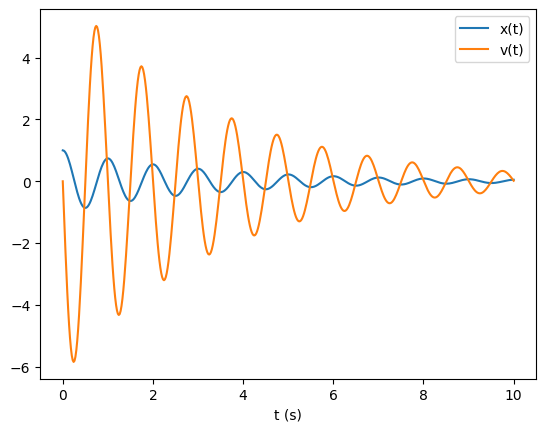

In [48]:
from scipy.integrate import solve_ivp

omega0 = 2 * np.pi * 1.0        # pulsation propre (rad/s)
lam = 0.3                       # coefficient d'amortissement (1/s)

def oscillateur(t, y):
    x, v = y
    return [v, -2 * lam * v - omega0**2 * x]

sol = solve_ivp(oscillateur, t_span=(0, 10), y0=[1.0, 0.0],
                t_eval=np.linspace(0, 10, 500))

plt.plot(sol.t, sol.y[0], label="x(t)")
plt.plot(sol.t, sol.y[1], label="v(t)")
plt.xlabel("t (s)")
plt.legend()
plt.show()

Le **portrait de phase** $(x, v)$ montre bien la spirale vers l'équilibre :

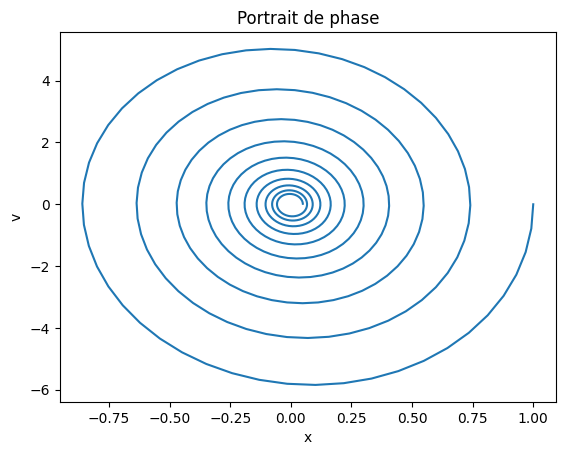

In [49]:
plt.plot(sol.y[0], sol.y[1])
plt.xlabel("x"); plt.ylabel("v")
plt.title("Portrait de phase")
plt.show()

**Le pendule : au-delà des petits angles.** Pour un pendule simple, $\ddot\theta = -\frac{g}{L}\sin\theta$. Comparons la solution exacte à l'approximation harmonique $\sin\theta \approx \theta$ pour un grand angle initial :

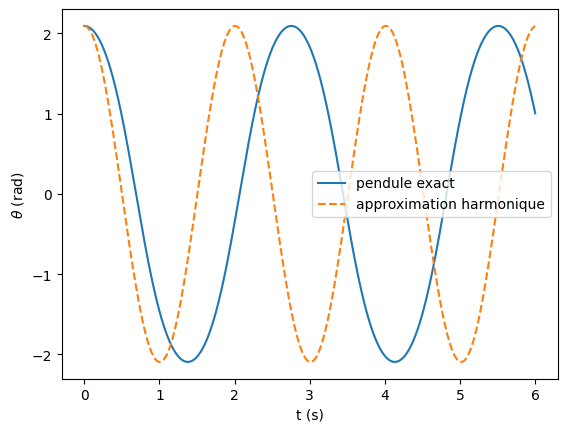

In [50]:
g, L = 9.81, 1.0
theta0 = np.radians(120)

def pendule(t, y):
    theta, omega = y
    return [omega, -(g / L) * np.sin(theta)]

t_eval = np.linspace(0, 6, 600)
sol = solve_ivp(pendule, (0, 6), [theta0, 0.0], t_eval=t_eval, rtol=1e-9)
theta_harm = theta0 * np.cos(np.sqrt(g / L) * t_eval)

plt.plot(t_eval, sol.y[0], label="pendule exact")
plt.plot(t_eval, theta_harm, '--', label="approximation harmonique")
plt.xlabel("t (s)"); plt.ylabel(r"$\theta$ (rad)")
plt.legend()
plt.show()

> **Exercice : chute avec frottements**
>
> Une balle de masse $m = 0{,}1$ kg est lâchée sans vitesse initiale, avec un frottement visqueux $-\alpha v$ ($\alpha = 0{,}2$ kg/s). L'équation est $m\dot v = mg - \alpha v$ (axe vers le bas).
>
> 1. Résolvez-la avec `solve_ivp` entre 0 et 3 s.
> 2. Comparez avec la solution analytique $v(t) = \frac{mg}{\alpha}\left(1 - e^{-\alpha t/m}\right)$.
> 3. Quelle est la vitesse limite ?

Vitesse limite = 4.905 m/s
Vitesse à t = 3 s = 4.893 m/s
Écart maximal numérique/analytique = 0.0006858269740659395 m/s


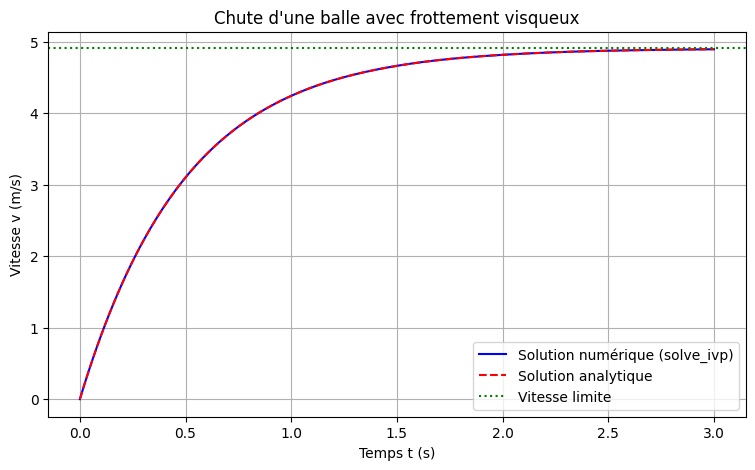

In [80]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Données physiques
m = 0.1        # Masse (kg)
alpha = 0.2    # Coefficient de frottement (kg/s)
g = 9.81       # Gravité (m/s²)

# 1. Équation différentielle : dv/dt = g - (alpha/m)*v
def equation(t, v):
    return [g - (alpha/m)*v[0]]

# Conditions initiales et intervalle de temps
t = np.linspace(0, 3, 300)

solution = solve_ivp(
    equation,
    [0, 3],
    [0],
    t_eval=t
)

v_numerique = solution.y[0]

# 2. Solution analytique
v_analytique = (m*g/alpha) * (1 - np.exp(-alpha*t/m))

# 3. Vitesse limite
v_limite = m*g/alpha

# Affichage des résultats
print("Vitesse limite =", round(v_limite, 3), "m/s")
print("Vitesse à t = 3 s =", round(v_analytique[-1], 3), "m/s")

print("Écart maximal numérique/analytique =",
      np.max(np.abs(v_numerique - v_analytique)), "m/s")

# Tracer les deux solutions
plt.figure(figsize=(9, 5))

plt.plot(t, v_numerique, 'b-',
         label="Solution numérique (solve_ivp)")

plt.plot(t, v_analytique, 'r--',
         label="Solution analytique")

plt.axhline(v_limite, color="green",
            linestyle=":", label="Vitesse limite")

plt.xlabel("Temps t (s)")
plt.ylabel("Vitesse v (m/s)")
plt.title("Chute d'une balle avec frottement visqueux")
plt.grid(True)
plt.legend()
plt.show()

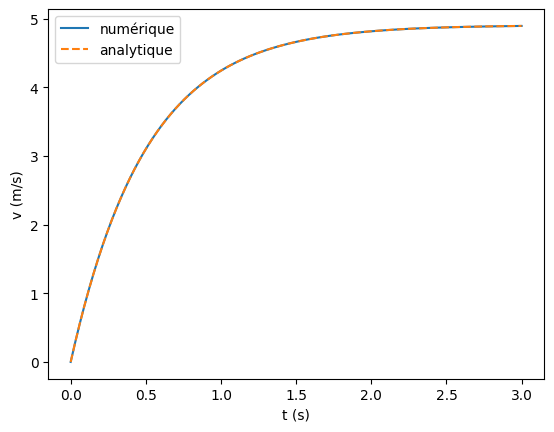

vitesse limite : 4.905 m/s


In [52]:
#@title Solution { display-mode: "form" }
m, alpha, g = 0.1, 0.2, 9.81
sol = solve_ivp(lambda t, v: g - alpha * v / m, (0, 3), [0.0],
                t_eval=np.linspace(0, 3, 100))
v_exact = (m * g / alpha) * (1 - np.exp(-alpha * sol.t / m))

plt.plot(sol.t, sol.y[0], label="numérique")
plt.plot(sol.t, v_exact, '--', label="analytique")
plt.xlabel("t (s)"); plt.ylabel("v (m/s)"); plt.legend()
plt.show()
print("vitesse limite :", m * g / alpha, "m/s")

# Transformées de Fourier rapides : `scipy.fft`

La **transformée de Fourier** décompose un signal en ses fréquences. Elle est indispensable pour analyser des signaux de mesure (oscilloscope, son, vibrations…).

Créons un signal composé de deux sinusoïdes (50 Hz et 120 Hz) et d'un bruit :

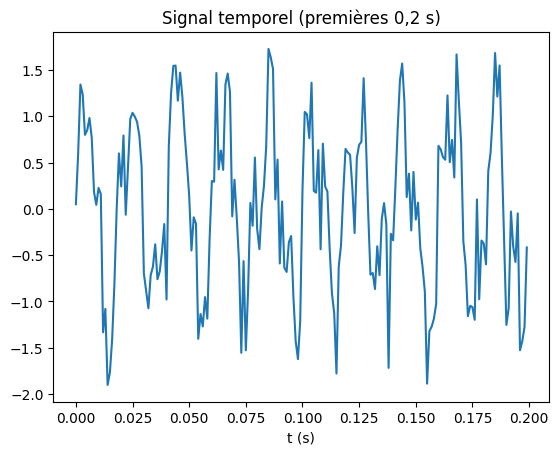

In [53]:
fs = 1000                                  # fréquence d'échantillonnage (Hz)
t = np.arange(0, 1, 1 / fs)                # 1 seconde de signal
rng = np.random.default_rng(0)
signal = (1.0 * np.sin(2 * np.pi * 50 * t)
          + 0.5 * np.sin(2 * np.pi * 120 * t)
          + 0.4 * rng.standard_normal(t.size))

plt.plot(t[:200], signal[:200])
plt.xlabel("t (s)")
plt.title("Signal temporel (premières 0,2 s)")
plt.show()

La TFD donne les composantes en fréquence. `rfft` (pour signaux réels) et `rfftfreq` (les fréquences correspondantes) :

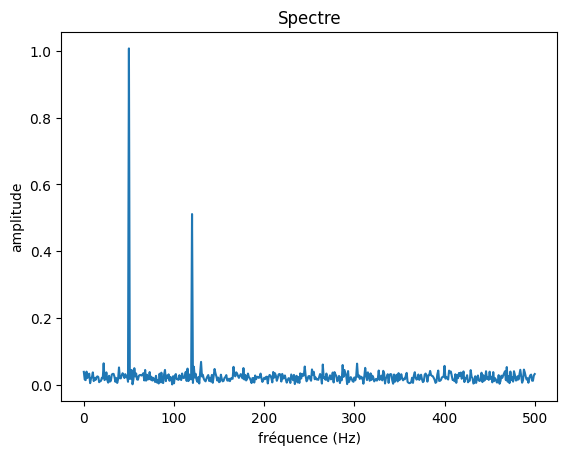

In [54]:
spectre = sp.fft.rfft(signal)
freqs = sp.fft.rfftfreq(signal.size, d=1 / fs)
amplitude = 2 * np.abs(spectre) / signal.size

plt.plot(freqs, amplitude)
plt.xlabel("fréquence (Hz)")
plt.ylabel("amplitude")
plt.title("Spectre")
plt.show()

Deux pics nets apparaissent à 50 Hz et 120 Hz, avec des amplitudes proches de 1 et 0,5, même si le signal temporel paraît confus.


> 📝 **Note**
>
> **Théorème de Shannon** : on ne peut détecter que les fréquences inférieures à la moitié de la fréquence d'échantillonnage ($f_s/2$, la fréquence de Nyquist). Au-delà, on observe du *repliement* de spectre (*aliasing*).


On peut aussi **filtrer** dans l'espace de Fourier. Supprimons tout ce qui est au-dessus de 80 Hz :

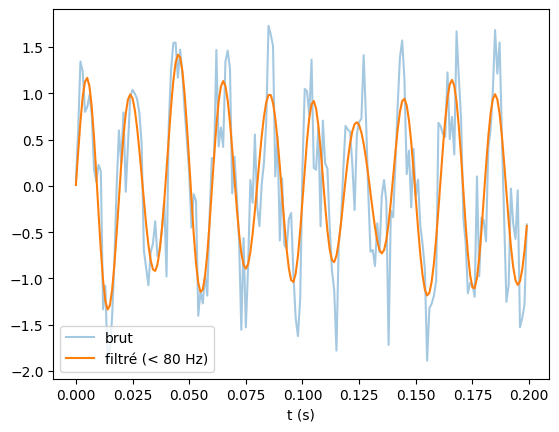

In [55]:
spectre_filtre = spectre.copy()
spectre_filtre[freqs > 80] = 0
signal_filtre = sp.fft.irfft(spectre_filtre, n=signal.size)

plt.plot(t[:200], signal[:200], alpha=0.4, label="brut")
plt.plot(t[:200], signal_filtre[:200], label="filtré (< 80 Hz)")
plt.xlabel("t (s)"); plt.legend()
plt.show()

> **Exercice**
>
> Générez un signal de fréquence 200 Hz échantillonné à $f_s = 300$ Hz (donc en dessous de la fréquence de Shannon). À quelle fréquence apparaît le pic dans le spectre ? Expliquez.

Fréquence réelle : 200 Hz
Fréquence d'échantillonnage : 300 Hz
Fréquence de Nyquist : 150.0 Hz
Pic observé : 100.0 Hz


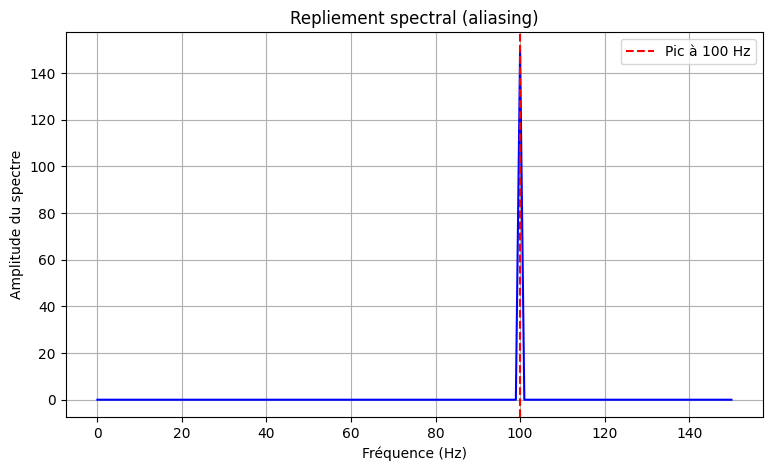

In [81]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import rfft, rfftfreq

# Données
f = 200       # Fréquence du signal (Hz)
fs = 300      # Fréquence d'échantillonnage (Hz)
N = 300       # Nombre d'échantillons

# Création du signal
t = np.arange(N) / fs
signal = np.sin(2 * np.pi * f * t)

# Transformée de Fourier
spectre = np.abs(rfft(signal))
frequences = rfftfreq(N, d=1/fs)

# Fréquence du pic spectral
indice_pic = np.argmax(spectre[1:]) + 1
f_pic = frequences[indice_pic]

print("Fréquence réelle :", f, "Hz")
print("Fréquence d'échantillonnage :", fs, "Hz")
print("Fréquence de Nyquist :", fs/2, "Hz")
print("Pic observé :", f_pic, "Hz")

# Tracé du spectre
plt.figure(figsize=(9, 5))
plt.plot(frequences, spectre, color="blue")
plt.axvline(f_pic, color="red", linestyle="--",
            label=f"Pic à {f_pic:.0f} Hz")

plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude du spectre")
plt.title("Repliement spectral (aliasing)")
plt.grid(True)
plt.legend()
plt.show()

In [57]:
#@title Solution { display-mode: "form" }
fs = 300
t = np.arange(0, 2, 1 / fs)
s = np.sin(2 * np.pi * 200 * t)
freqs = sp.fft.rfftfreq(s.size, 1 / fs)
amp = np.abs(sp.fft.rfft(s))
print("pic à", freqs[amp.argmax()], "Hz")   # 100 Hz = |200 - 300| : repliement de spectre

pic à 100.0 Hz


# Traitement du signal : `scipy.signal`

`scipy.signal` propose des outils pour le filtrage, la détection de pics, la convolution, etc.

**Détection de pics** dans un spectre ou une courbe de mesure :

In [58]:
from scipy.signal import find_peaks

pics, _ = find_peaks(amplitude, height=0.2)
freqs[pics], amplitude[pics]

(array([25., 60.]), array([1.00698255, 0.51094312]))

**Filtrage** : un filtre passe-bas de Butterworth, appliqué à notre signal bruité :

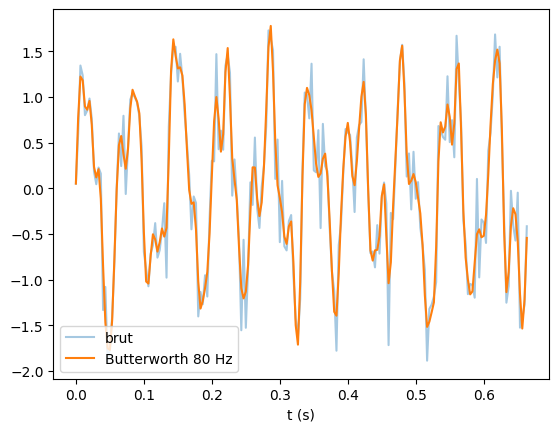

In [59]:
from scipy.signal import butter, filtfilt

b, a = butter(N=4, Wn=80, btype='low', fs=fs)   # coupure à 80 Hz
signal_butter = filtfilt(b, a, signal)

plt.plot(t[:200], signal[:200], alpha=0.4, label="brut")
plt.plot(t[:200], signal_butter[:200], label="Butterworth 80 Hz")
plt.xlabel("t (s)"); plt.legend()
plt.show()

**Lissage** par moyenne glissante (convolution) :

In [60]:
fenetre = np.ones(10) / 10
signal_lisse = np.convolve(signal, fenetre, mode='same')

# Traitement d'images : `scipy.ndimage`

Le module `scipy.ndimage` regroupe des opérations sur des tableaux n-dimensionnels, notamment des images : filtres, morphologie mathématique, mesures sur des objets. Un exemple rapide sur une image synthétique :

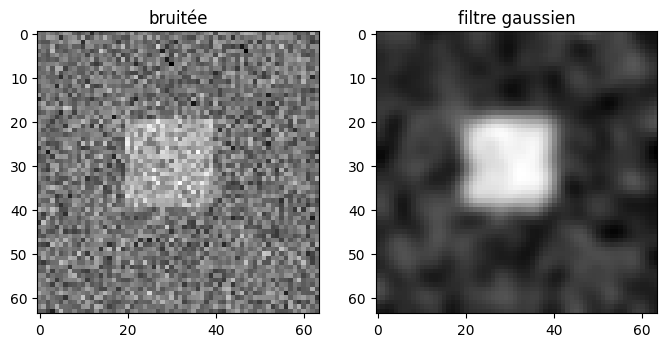

In [61]:
from scipy import ndimage

rng = np.random.default_rng(0)
image = np.zeros((64, 64))
image[20:40, 20:40] = 1.0
image += 0.5 * rng.standard_normal(image.shape)
lissee = ndimage.gaussian_filter(image, sigma=2)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(image, cmap='gray');  axes[0].set_title("bruitée")
axes[1].imshow(lissee, cmap='gray'); axes[1].set_title("filtre gaussien")
plt.show()

Pour aller plus loin en traitement d'images, voir la bibliothèque **scikit-image**.

# Exercice de synthèse : analyse d'une expérience

Un oscillateur amorti a été enregistré (position en fonction du temps) avec du bruit. Simulons cette « expérience » :

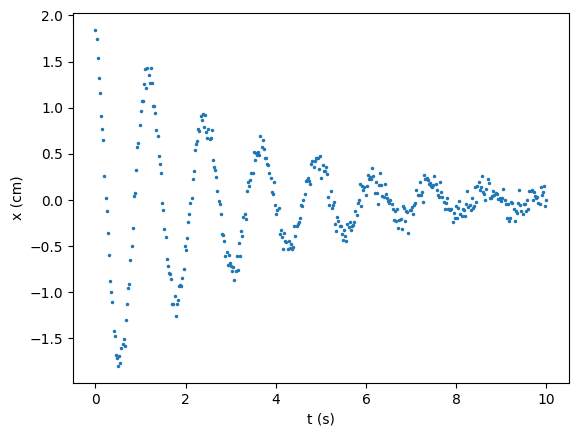

In [62]:
rng = np.random.default_rng(7)
t = np.linspace(0, 10, 400)
x_vrai = 2.0 * np.exp(-t / 3.0) * np.cos(2 * np.pi * 0.8 * t + 0.4)
x_mesure = x_vrai + rng.normal(0, 0.08, t.size)
plt.plot(t, x_mesure, '.', ms=3)
plt.xlabel("t (s)"); plt.ylabel("x (cm)")
plt.show()

1. **Ajustez** le modèle $x(t) = A e^{-t/\tau} \cos(2\pi f t + \varphi)$ avec `curve_fit`. Donnez $A$, $\tau$, $f$ et $\varphi$ avec leurs incertitudes.
2. **Vérifiez par la TFD** : le pic du spectre est-il proche de la fréquence ajustée ?
3. **Tracez** les données, l'ajustement et les résidus (différence mesure − modèle) dans deux sous-graphiques.

PARAMÈTRES AJUSTÉS
A   = 2.0290 ± 0.0199 cm
tau = 3.0253 ± 0.0420 s
f   = 0.8004 ± 0.0007 Hz
phi = 0.3990 ± 0.0092 rad

VÉRIFICATION PAR LA TFD
Fréquence ajustée = 0.8004 Hz
Pic de la TFD     = 0.7980 Hz


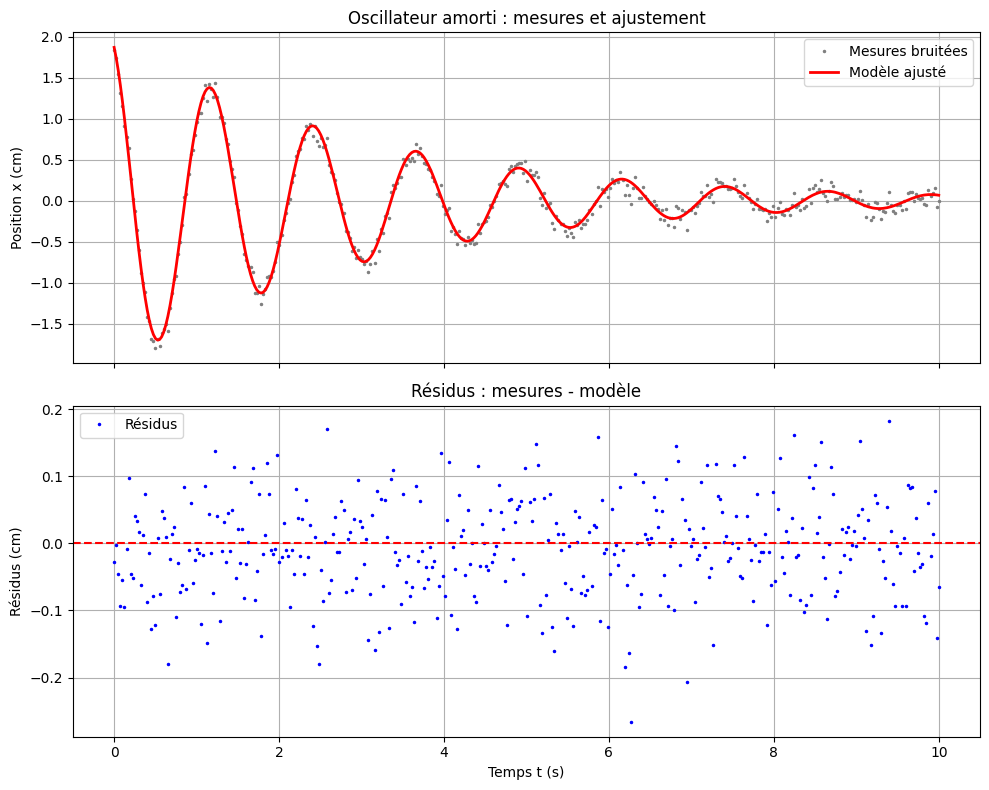

In [82]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.fft import rfft, rfftfreq

# ==========================================
# 1. Simulation de l'expérience
# ==========================================

rng = np.random.default_rng(7)

t = np.linspace(0, 10, 400)

x_vrai = 2.0 * np.exp(-t / 3.0) * np.cos(
    2 * np.pi * 0.8 * t + 0.4
)

x_mesure = x_vrai + rng.normal(0, 0.08, t.size)

# ==========================================
# 2. Ajustement avec curve_fit
# ==========================================

def modele(t, A, tau, f, phi):
    return A * np.exp(-t / tau) * np.cos(
        2 * np.pi * f * t + phi
    )

# Valeurs initiales des paramètres
p0 = [2.0, 3.0, 0.8, 0.4]

parametres, covariance = curve_fit(
    modele, t, x_mesure,
    p0=p0,
    bounds=([0, 0.01, 0, -np.pi],
            [np.inf, np.inf, np.inf, np.pi])
)

A, tau, f, phi = parametres

# Incertitudes-types des paramètres
incertitudes = np.sqrt(np.diag(covariance))

# Valeurs ajustées et résidus
x_ajuste = modele(t, *parametres)
residus = x_mesure - x_ajuste

print("PARAMÈTRES AJUSTÉS")
print(f"A   = {A:.4f} ± {incertitudes[0]:.4f} cm")
print(f"tau = {tau:.4f} ± {incertitudes[1]:.4f} s")
print(f"f   = {f:.4f} ± {incertitudes[2]:.4f} Hz")
print(f"phi = {phi:.4f} ± {incertitudes[3]:.4f} rad")

# ==========================================
# 3. Vérification par la TFD
# ==========================================

dt = t[1] - t[0]

frequences = rfftfreq(t.size, d=dt)
spectre = np.abs(rfft(x_mesure - np.mean(x_mesure)))

indice_pic = np.argmax(spectre[1:]) + 1
f_TFD = frequences[indice_pic]

print("\nVÉRIFICATION PAR LA TFD")
print(f"Fréquence ajustée = {f:.4f} Hz")
print(f"Pic de la TFD     = {f_TFD:.4f} Hz")

# ==========================================
# 4. Tracé des deux sous-graphiques
# ==========================================

fig, ax = plt.subplots(2, 1, figsize=(10, 8),
                       sharex=True)

# Premier graphique : mesures et ajustement
ax[0].plot(t, x_mesure, ".", color="gray",
           markersize=3, label="Mesures bruitées")

ax[0].plot(t, x_ajuste, "r-", linewidth=2,
           label="Modèle ajusté")

ax[0].set_title("Oscillateur amorti : mesures et ajustement")
ax[0].set_ylabel("Position x (cm)")
ax[0].legend()
ax[0].grid(True)

# Deuxième graphique : résidus
ax[1].plot(t, residus, "b.", markersize=3,
           label="Résidus")

ax[1].axhline(0, color="red", linestyle="--")

ax[1].set_title("Résidus : mesures - modèle")
ax[1].set_xlabel("Temps t (s)")
ax[1].set_ylabel("Résidus (cm)")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

A    = 2.029 ± 0.020
tau  = 3.025 ± 0.042
f    = 0.800 ± 0.001
phi  = 0.399 ± 0.009
pic TFD à 0.798 Hz


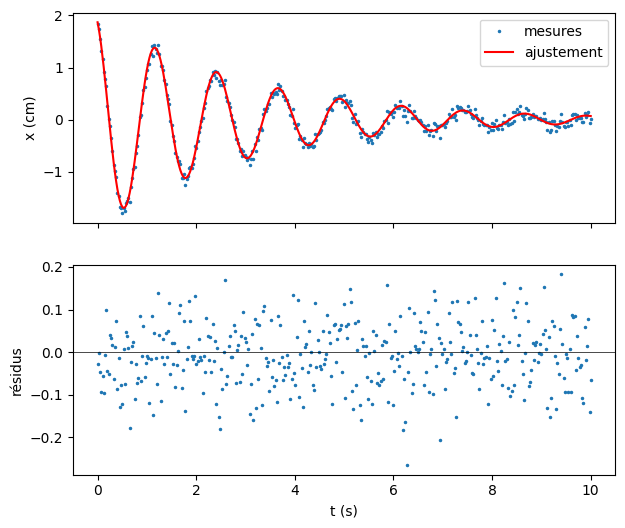

In [64]:
#@title Solution { display-mode: "form" }
def modele(t, A, tau, f, phi):
    return A * np.exp(-t / tau) * np.cos(2 * np.pi * f * t + phi)

popt, pcov = sp.optimize.curve_fit(modele, t, x_mesure, p0=[1.5, 2, 0.7, 0])
inc = np.sqrt(np.diag(pcov))
for nom, v, u in zip(["A", "tau", "f", "phi"], popt, inc):
    print(f"{nom:4s} = {v:.3f} ± {u:.3f}")

# TFD
freqs = sp.fft.rfftfreq(t.size, d=t[1] - t[0])
spec = np.abs(sp.fft.rfft(x_mesure))
print("pic TFD à", freqs[spec.argmax()], "Hz")

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 6))
ax1.plot(t, x_mesure, '.', ms=3, label="mesures")
ax1.plot(t, modele(t, *popt), 'r', label="ajustement")
ax1.set_ylabel("x (cm)"); ax1.legend()
ax2.plot(t, x_mesure - modele(t, *popt), '.', ms=3)
ax2.axhline(0, color='k', lw=0.5)
ax2.set_ylabel("résidus"); ax2.set_xlabel("t (s)")
plt.show()

# Pour aller plus loin

- La [documentation de SciPy](https://docs.scipy.org/doc/scipy/) et son [tutoriel](https://docs.scipy.org/doc/scipy/tutorial/index.html).
- Le [SciPy Cookbook](https://scipy-cookbook.readthedocs.io) : une collection de recettes.

---

*Fin du carnet 5. Suite : carnet 6 — SymPy (calcul symbolique).*